# 03 · Significance, false positives and power

How many "significant" results are real, and are the tests big enough to find real effects?

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import upworthy as uw

pd.set_option("display.max_columns", None)
uw.FIG_DIR.mkdir(parents=True, exist_ok=True)

con = uw.connect()

arms = uw.load_arms(con)

## 1. One test, done properly

CTR with a 95% Wilson interval for each arm, then a chi-square test of "all arms have the same CTR".

In [2]:
example_id = (
    arms[~arms["is_aa"]]
    .groupby("test_id")["impressions"].sum()
    .sort_values(ascending=False).index[10]
)
ex = arms[arms["test_id"] == example_id].copy()
ex["ci_low"], ex["ci_high"] = uw.wilson_ci(ex["clicks"], ex["impressions"])
ex[["headline", "impressions", "clicks", "ctr", "ci_low", "ci_high", "upworthy_winner"]].sort_values("ctr", ascending=False).round(4)

,headline,impressions,clicks,ctr,ci_low,ci_high,upworthy_winner
12716,This Ad Campaign Manages To Insult Single Wome...,7574,77,0.0102,0.0081,0.0127,True
12720,This Ad Campaign Manages To Insult Single Wome...,7661,70,0.0091,0.0072,0.0115,False
12717,This Ad Campaign Manages To Insult Single Wome...,7654,69,0.0090,0.0071,0.0114,False
12718,This Ad Campaign Manages To Insult Single Wome...,7699,66,0.0086,0.0067,0.0109,False
12719,This Ad Campaign Manages To Insult Single Wome...,7669,61,0.0080,0.0062,0.0102,False
12721,This Ad Campaign Manages To Insult Single Wome...,7700,56,0.0073,0.0056,0.0094,False
12722,This Ad Campaign Manages To Insult Single Wome...,7838,55,0.0070,0.0054,0.0091,False


In [3]:
from scipy import stats

table = np.vstack([ex["clicks"], ex["impressions"] - ex["clicks"]])
chi2, p, dof, _ = stats.chi2_contingency(table, correction=False)
print(f"chi2 = {chi2:.2f}, df = {dof}, p = {p:.4f}")

chi2 = 6.83, df = 6, p = 0.3371


## 2. Calibration check with A/A tests

In A/A tests every arm is identical, so a valid test should flag about 5% of them at p < 0.05.

In [4]:
chi = uw.per_test_chi2(arms)
chi["p_naive"] = stats.chi2.sf(chi["chi2"], chi["df"])

chi.groupby("is_aa")["p_naive"].apply(lambda p: (p < 0.05).mean()).rename("share_p<0.05").round(3)

is_aa
False    0.488
True     0.228
Name: share_p<0.05, dtype: float64

The naive binomial test flags far more than 5% of A/A tests, so it understates the noise.
CTRs vary more than a binomial model allows (traffic changes over the day, different audiences, etc.).
We estimate this **overdispersion factor** φ from the A/A tests and scale the test statistic by it.

In [5]:
phi = uw.estimate_dispersion(chi)
chi["p_adjusted"] = stats.chi2.sf(chi["chi2"] / phi, chi["df"])

print(f"Overdispersion phi = {phi:.2f}  (1.0 would mean binomial is fine)")
chi.groupby("is_aa")[["p_naive", "p_adjusted"]].agg(lambda p: (p < 0.05).mean()).round(3)

Overdispersion phi = 1.83  (1.0 would mean binomial is fine)


,p_naive,p_adjusted
is_aa,,
False,0.488,0.241
True,0.228,0.071


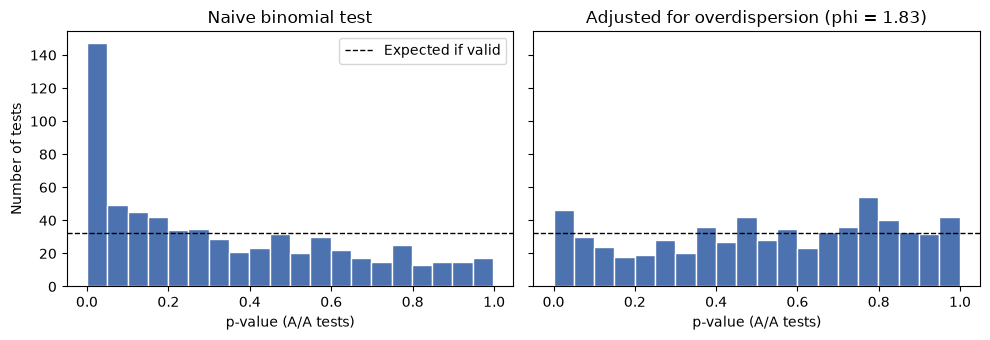

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
aa = chi[chi["is_aa"]]
for ax, col, title in zip(axes, ["p_naive", "p_adjusted"], ["Naive binomial test", f"Adjusted for overdispersion (phi = {phi:.2f})"]):
    ax.hist(aa[col], bins=20, color="#4C72B0", edgecolor="white")
    ax.axhline(len(aa) / 20, color="black", linestyle="--", linewidth=1, label="Expected if valid")
    ax.set_title(title)
    ax.set_xlabel("p-value (A/A tests)")
axes[0].set_ylabel("Number of tests")
axes[0].legend()
fig.tight_layout()
fig.savefig(uw.FIG_DIR / "aa_pvalues.png", dpi=150)
plt.show()

## 3. Multiple testing across thousands of experiments

With thousands of tests, some will look significant by chance. Benjamini-Hochberg controls the share of false discoveries.

In [7]:
real = chi[~chi["is_aa"]].copy()
real["q_naive"] = uw.benjamini_hochberg(real["p_naive"])
real["q_adjusted"] = uw.benjamini_hochberg(real["p_adjusted"])

summary = pd.DataFrame({
    "p < 0.05": [(real["p_naive"] < 0.05).sum(), (real["p_adjusted"] < 0.05).sum()],
    "BH q < 0.10": [(real["q_naive"] < 0.10).sum(), (real["q_adjusted"] < 0.10).sum()],
}, index=["naive", "overdispersion-adjusted"])
summary["out of"] = len(real)
summary

,p < 0.05,BH q < 0.10,out of
naive,1550,1544,3176
overdispersion-adjusted,767,541,3176


In [8]:
pi0 = uw.storey_pi0(real["p_adjusted"])
print(f"Estimated share of tests where all arms perform the same: {pi0:.0%}")

Estimated share of tests where all arms perform the same: 66%


## 4. Power: how big an effect could these tests detect?

In [9]:
typical_ctr = arms["clicks"].sum() / arms["impressions"].sum()
typical_n = arms["impressions"].median()

mde_naive = uw.mde_two_arm(typical_ctr, typical_n)
mde_adj = uw.mde_two_arm(typical_ctr, typical_n, phi=phi)
print(f"Typical CTR {typical_ctr:.4f}, typical impressions per arm {typical_n:,.0f}")
print(f"Minimum detectable relative lift (80% power, alpha 0.05): "
      f"{mde_naive / typical_ctr:.0%} naive, {mde_adj / typical_ctr:.0%} after overdispersion")

Typical CTR 0.0131, typical impressions per arm 3,118
Minimum detectable relative lift (80% power, alpha 0.05): 61% naive, 83% after overdispersion


In [10]:
lifts = [0.05, 0.10, 0.20, 0.30, 0.50]
pd.DataFrame({
    "relative lift": [f"{l:.0%}" for l in lifts],
    "impressions per arm needed": [f"{uw.n_per_arm_needed(typical_ctr, l, phi=phi):,.0f}" for l in lifts],
})

,relative lift,impressions per arm needed
0,5%,"861,663"
1,10%,"215,416"
2,20%,"53,854"
3,30%,"23,936"
4,50%,"8,617"


**Findings.**
- The naive test has an inflated false-positive rate; correcting for overdispersion brings A/A tests close to the nominal 5%.
- After the correction, far fewer real tests show a significant difference.
- Typical tests can only detect very large lifts, so small real improvements are mostly invisible.